# Air Demand Gap Finder

**Mission:** Show airlines, airports and investors where African air travel is under-served compared with what a country's economy can support.

**Use case:** Predict how many air passengers a country carries in a year from its economic indicators. A real number far below the prediction marks a demand gap worth investigating.

**Data:** World Bank World Development Indicators (air data from ICAO) plus the World Bank country classification (region, income group).
- https://databank.worldbank.org/source/world-development-indicators
- https://datahelpdesk.worldbank.org/knowledgebase/articles/906519

## 0. Get the data
Create a `data` folder next to this notebook with two files:
- `wdi_data.csv`: DataBank CSV, all countries, 1990 to 2023, series `IS.AIR.PSGR` (target), `NY.GDP.PCAP.CD`, `NY.GDP.MKTP.KD.ZG`, `SP.POP.TOTL`, `SP.URB.TOTL`, `SP.URB.TOTL.IN.ZS`, `SP.URB.GROW`, `IT.NET.USER.ZS`, `ST.INT.RCPT.XP.ZS`, `ST.INT.XPND.MP.ZS`, `NE.TRD.GNFS.ZS`, `AG.LND.TOTL.K2`, `BX.KLT.DINV.WD.GD.ZS`.
- `country_classes.xlsx`: the World Bank classification file.

## 1. Load the data

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, os
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_val_predict
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
from sklearn.metrics import mean_squared_error, r2_score

# one row per country and indicator -> one row per country and year
raw = pd.read_csv("data/wdi_data.csv", na_values="..").dropna(subset=["Series Code"])
years = [c for c in raw.columns if "[YR" in c]
long = raw.melt(id_vars=["Country Name", "Country Code", "Series Code"], value_vars=years, var_name="year")
long["year"] = long["year"].str[:4].astype(int)
df = long.pivot_table(index=["Country Name", "Country Code", "year"], columns="Series Code", values="value").reset_index()

classes = pd.read_excel("data/country_classes.xlsx")[["Code", "Region", "Income group"]]
df = df.merge(classes, left_on="Country Code", right_on="Code").drop(columns="Code")
df = df.rename(columns={
    "IS.AIR.PSGR": "passengers", "NY.GDP.PCAP.CD": "gdp_per_capita", "NY.GDP.MKTP.KD.ZG": "gdp_growth",
    "SP.POP.TOTL": "population", "SP.URB.TOTL": "urban_pop", "SP.URB.TOTL.IN.ZS": "urban_pct",
    "SP.URB.GROW": "urban_growth", "IT.NET.USER.ZS": "internet_pct", "ST.INT.RCPT.XP.ZS": "tourism_receipts_pct",
    "ST.INT.XPND.MP.ZS": "tourism_spend_pct", "NE.TRD.GNFS.ZS": "trade_pct", "AG.LND.TOTL.K2": "land_area",
    "BX.KLT.DINV.WD.GD.ZS": "fdi_pct", "Region": "region", "Income group": "income_group"})

# drop groups like "World" (no region) and zero passengers (no national airline)
df = df.dropna(subset=["passengers", "region"])
df = df[df["passengers"] > 0].reset_index(drop=True)
print(df.shape)
df.head()

(5211, 18)


,Country Name,Country Code,year,land_area,fdi_pct,passengers,internet_pct,trade_pct,gdp_growth,gdp_per_capita,population,urban_growth,urban_pop,urban_pct,tourism_receipts_pct,tourism_spend_pct,region,income_group
0,Afghanistan,AFG,1990,652230.0,NaN,241400.0,0.0,NaN,NaN,NaN,12045660.0,2.105964,2079567.0,17.264035,NaN,NaN,"Middle East, North Africa, Afghanistan & Pakistan",Low income
1,Afghanistan,AFG,1991,652230.0,NaN,212300.0,NaN,NaN,NaN,NaN,12238879.0,2.241555,2126708.0,17.376660,NaN,NaN,"Middle East, North Africa, Afghanistan & Pakistan",Low income
2,Afghanistan,AFG,1992,652230.0,NaN,212300.0,NaN,NaN,NaN,NaN,13278974.0,8.796302,2322254.0,17.488203,NaN,NaN,"Middle East, North Africa, Afghanistan & Pakistan",Low income
3,Afghanistan,AFG,1993,652230.0,NaN,197000.0,NaN,NaN,NaN,NaN,14943172.0,12.447144,2630068.0,17.600467,NaN,NaN,"Middle East, North Africa, Afghanistan & Pakistan",Low income
4,Afghanistan,AFG,1994,652230.0,NaN,238400.0,NaN,NaN,NaN,NaN,16250794.0,9.038815,2878870.0,17.715260,NaN,NaN,"Middle East, North Africa, Afghanistan & Pakistan",Low income


5,211 rows from 184 countries (1990 to 2023). We removed regional groups like "World" and 22 rows with zero passengers (no national airline).

## 2. Explore the data

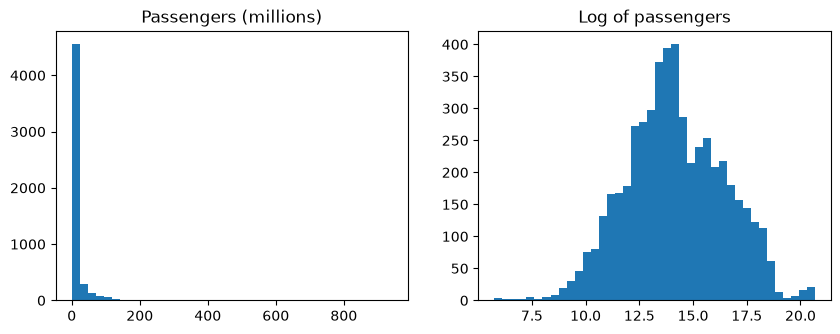

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(df["passengers"] / 1e6, bins=40); ax[0].set_title("Passengers (millions)")
ax[1].hist(np.log1p(df["passengers"]), bins=40); ax[1].set_title("Log of passengers")
plt.show()

Most countries carry few passengers and a few carry hundreds of millions. After the log the shape is balanced, so the models predict the **log of passengers**.

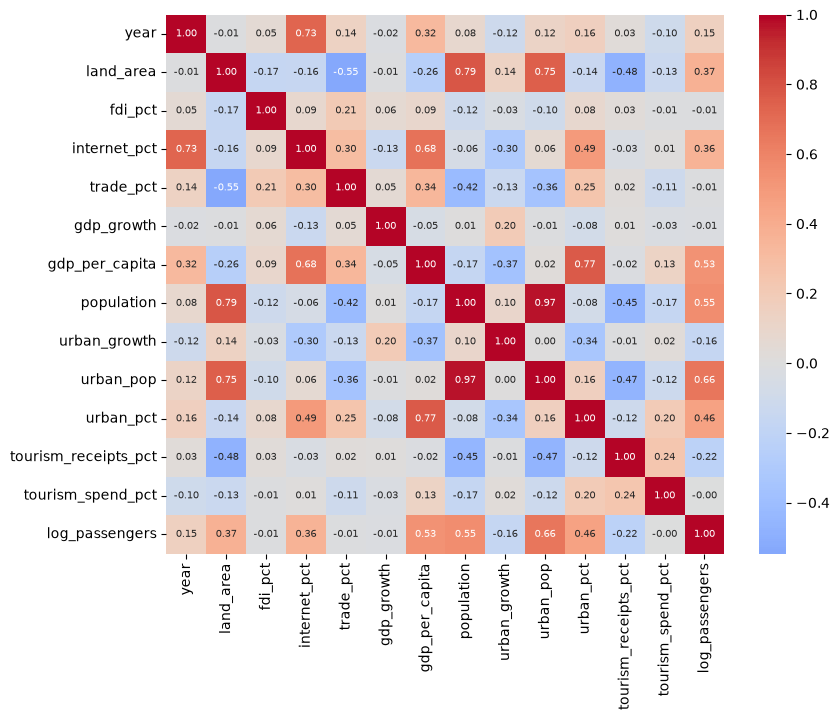

In [3]:
# log the skewed columns, so the heatmap shows what the models will use
log_cols = ["gdp_per_capita", "population", "land_area", "urban_pop"]
eda = df.copy()
eda[log_cols] = np.log(eda[log_cols])
eda["log_passengers"] = np.log1p(eda["passengers"])
corr = eda.drop(columns="passengers").select_dtypes("number").corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 7})
plt.show()

Urban population and population are 0.97 correlated, so we keep only population. Trade, FDI, GDP growth and tourism spending have almost no link to passengers, so we drop them.

## 3. Feature engineering

In [4]:
numeric = ["gdp_per_capita", "population", "land_area", "urban_pct", "internet_pct", "tourism_receipts_pct", "year"]
categorical = ["region", "income_group"]
log_features = ["gdp_per_capita", "population", "land_area"]   # logged inside the pipeline

X, y, countries = df[numeric + categorical], df["passengers"], df["Country Code"]

**Kept:** GDP per capita, population, land area, urban %, internet %, tourism receipts %, year, region, income group.

**Dropped:**
- `urban_pop`: repeats `population`.
- `trade_pct`, `fdi_pct`, `gdp_growth`, `tourism_spend_pct`: no link to the target.
- `urban_growth`: weak link.
- Country names and codes: identifiers, used only to split the data.

The features that matter most are shown at the end (section 7).

## 4. Split, convert and standardize

We split by country, so every test country is unseen. A random split would put the same country in train and test and make the scores look better than they are. All preprocessing is fitted on the training set only.

In [5]:
# split by country: the test countries are never seen in training
split = GroupShuffleSplit(test_size=0.2, random_state=42)
train_idx, test_idx = next(split.split(X, y, groups=countries))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# fill gaps, log, standardize and one-hot encode (fitted on the training set only)
plain = [c for c in numeric if c not in log_features]
steps = lambda *extra: Pipeline([("fill", SimpleImputer(strategy="median")), *extra, ("scale", StandardScaler())])
prep = ColumnTransformer([
    ("logged", steps(("log", FunctionTransformer(np.log, feature_names_out="one-to-one"))), log_features),
    ("plain", steps(), plain),
    ("cats", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)])

# the models learn the log of passengers
Xtr, Xte = prep.fit_transform(X_train), prep.transform(X_test)
ytr, yte = np.log1p(y_train).values, np.log1p(y_test).values

## 5. Train and compare four models

### Tune SGDRegressor
We pick the settings on a validation set taken from the training data, so the test set stays untouched.

In [6]:
a, b = next(GroupShuffleSplit(test_size=0.2, random_state=1).split(Xtr, groups=countries.iloc[train_idx]))

rows = []
for lr in [0.0001, 0.001, 0.01]:
    for alpha in [0, 0.001, 0.1]:
        m = SGDRegressor(learning_rate="constant", eta0=lr, alpha=alpha, random_state=0)
        for epoch in range(1, 101):
            m.partial_fit(Xtr[a], ytr[a])
            if epoch in (10, 50, 100):
                rows.append([lr, alpha, epoch, mean_squared_error(ytr[b], m.predict(Xtr[b]))])

tuning = pd.DataFrame(rows, columns=["learning_rate", "alpha", "epochs", "val_mse"])
best = tuning.loc[tuning["val_mse"].idxmin()]
print("Best:", best.to_dict())
for col in ["learning_rate", "alpha", "epochs"]:
    print(tuning.groupby(col)["val_mse"].min().round(3))

Best: {'learning_rate': 0.0001, 'alpha': 0.001, 'epochs': 100.0, 'val_mse': 1.1908100409537479}
learning_rate
0.0001    1.191
0.0010    1.193
0.0100    1.520
Name: val_mse, dtype: float64
alpha
0.000    1.191
0.001    1.191
0.100    1.258
Name: val_mse, dtype: float64
epochs
10     1.210
50     1.193
100    1.191
Name: val_mse, dtype: float64


Learning rate 0.01 was worst (1.52): the steps are too big. 0.0001 and 0.001 were best (1.19). Alpha up to 0.001 changed nothing and 0.1 hurt (1.26). More epochs helped slightly (1.21 at 10, 1.19 at 100).

**Chosen:** learning rate 0.0001, alpha 0.001, 100 epochs.

### Loss curve

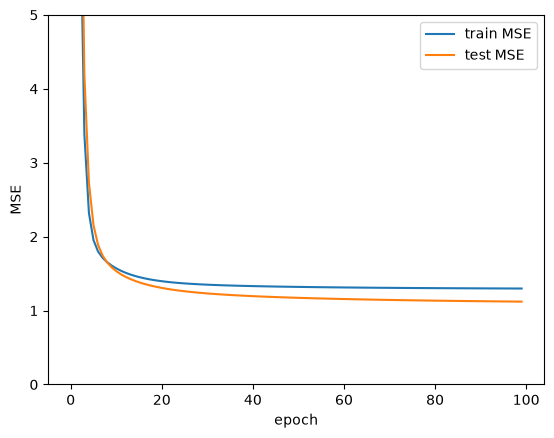

In [7]:
sgd = SGDRegressor(learning_rate="constant", eta0=best["learning_rate"], alpha=best["alpha"], random_state=0)
train_loss, test_loss = [], []
for epoch in range(int(best["epochs"])):
    sgd.partial_fit(Xtr, ytr)
    train_loss.append(mean_squared_error(ytr, sgd.predict(Xtr)))
    test_loss.append(mean_squared_error(yte, sgd.predict(Xte)))

plt.plot(train_loss, label="train MSE"); plt.plot(test_loss, label="test MSE")
plt.ylim(0, 5)   # the first epochs are huge, so we zoom in
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.show()

Both losses drop fast in the first 10 epochs, then flatten and stay close together. The model is not overfitting.

### Compare the four models

In [8]:
models = {
    "SGDRegressor (tuned)": sgd,
    "LinearRegression": LinearRegression().fit(Xtr, ytr),
    "DecisionTree": DecisionTreeRegressor(max_depth=8, random_state=0).fit(Xtr, ytr),
    "RandomForest": RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1).fit(Xtr, ytr)}

table = pd.DataFrame({name: [mean_squared_error(ytr, m.predict(Xtr)), mean_squared_error(yte, m.predict(Xte))]
                      for name, m in models.items()}, index=["train MSE", "test MSE"]).T.round(3)
table["R2 test"] = [round(r2_score(yte, m.predict(Xte)), 3) for m in models.values()]
best_name = table["test MSE"].idxmin()
print(table)
print("\nBest model (lowest test MSE):", best_name)

                      train MSE  test MSE  R2 test
SGDRegressor (tuned)      1.298     1.121    0.818
LinearRegression          1.290     0.879    0.857
DecisionTree              0.488     1.835    0.702
RandomForest              0.034     1.399    0.772

Best model (lowest test MSE): LinearRegression


**Best model: LinearRegression** (test MSE 0.879, R² 0.857). The tuned SGD is close (1.121). The tree and forest fit the training data very well but do worse on unseen countries (1.835 and 1.399): they memorize countries.

Passengers rise in a straight line with log population and log GDP, which suits a linear model. A test MSE of 0.88 means predictions are typically off by a factor of about 2.5: good for ranking countries, not for exact forecasts.

### Scatter plots

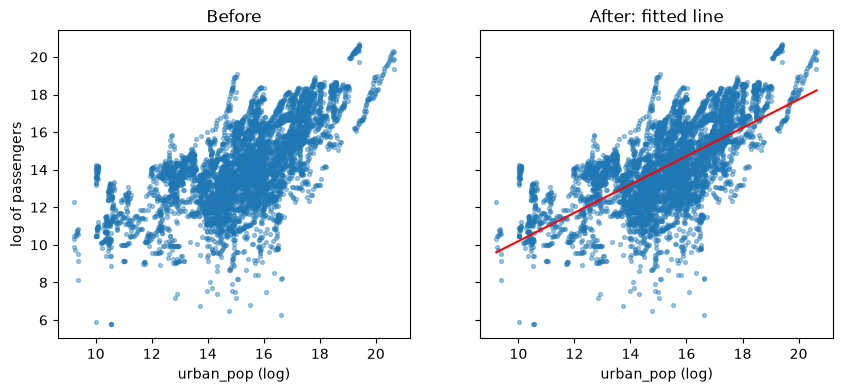

In [9]:
top = corr["log_passengers"].drop(["log_passengers", "year"]).abs().idxmax()   # most correlated feature
xs, ys = eda[[top]].sort_values(top), eda.loc[eda[top].sort_values().index, "log_passengers"]
line = LinearRegression().fit(xs, ys)   # one feature, for this plot only

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].scatter(xs, ys, s=8, alpha=0.4); ax[0].set_title("Before")
ax[1].scatter(xs, ys, s=8, alpha=0.4); ax[1].plot(xs, line.predict(xs), color="red"); ax[1].set_title("After: fitted line")
for a_ in ax: a_.set_xlabel(top + " (log)")
ax[0].set_ylabel("log of passengers"); plt.show()

Urban population (logged) is the feature most correlated with passengers (0.66). The line follows the trend, but the wide spread shows one feature is not enough.

## 6. Save the best model and predict one row

In [10]:
# preprocessing + best model in one pipeline; it takes raw values and returns passengers
pipe = Pipeline([("prep", prep), ("model", TransformedTargetRegressor(
    regressor=clone(models[best_name]), func=np.log1p, inverse_func=np.expm1))])
pipe.fit(X_train, y_train)

# the data is saved too, so the API can retrain on old plus new rows
os.makedirs("../API", exist_ok=True)
joblib.dump({"model": pipe, "data": df[numeric + categorical + ["passengers"]]}, "../API/best_model.pkl")

def predict_row(i):
    """Load the saved model and predict one row of the test set."""
    model = joblib.load("../API/best_model.pkl")["model"]
    row = X_test.iloc[[i]]
    print(df.loc[row.index[0], "Country Name"], int(row["year"].iloc[0]))
    print(f"Predicted: {model.predict(row)[0]:,.0f} | Actual: {y_test.iloc[i]:,.0f}")

predict_row(0)

Australia 1990
Predicted: 28,052,602 | Actual: 17,553,400


The file holds the full pipeline and the data, so the API takes raw values and can retrain. Example: Australia 1990, predicted 28.1 million, actual 17.6 million.

## 7. Extra: which African countries are under-served?

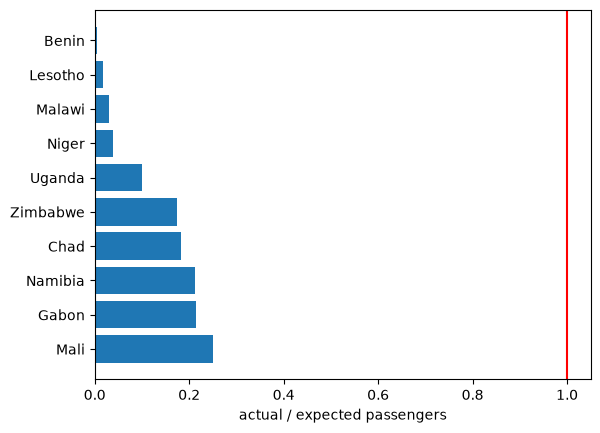

      year  passengers  predicted  actual_vs_expected
3927  2023  1537007.68   76946.22               19.98


In [11]:
# each country is predicted by a model that never saw it
df["predicted"] = np.expm1(cross_val_predict(clone(pipe), X, np.log1p(y), groups=countries, cv=GroupKFold(5)))
africa = df.sort_values("year").groupby("Country Code").tail(1)
africa = africa[africa["region"] == "Sub-Saharan Africa"].copy()
africa["actual_vs_expected"] = africa["passengers"] / africa["predicted"]

low = africa.sort_values("actual_vs_expected").head(10)
plt.barh(low["Country Name"], low["actual_vs_expected"]); plt.axvline(1, color="red")
plt.gca().invert_yaxis(); plt.xlabel("actual / expected passengers"); plt.show()
print(africa.loc[africa["Country Name"] == "Rwanda", ["year", "passengers", "predicted", "actual_vs_expected"]].round(2))

Each bar is actual divided by expected passengers (1 = as expected). Benin, Lesotho, Malawi, Niger and Uganda are far below. Rwanda is about 20 times above, thanks to its active national airline. Use this as a screening list: the data only count airlines registered in each country.

### Which features matter most?

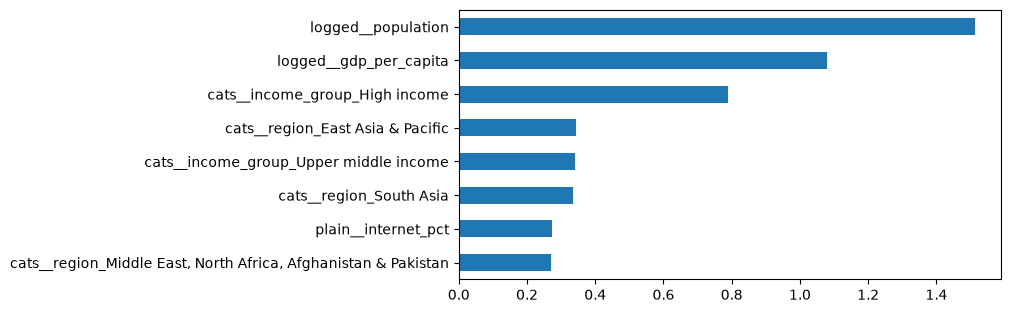

logged__population                    1.51
logged__gdp_per_capita                1.08
cats__income_group_Low income         0.96
cats__income_group_High income        0.79
cats__region_Europe & Central Asia    0.60
dtype: float64


In [12]:
coefs = pd.Series(pipe.named_steps["model"].regressor_.coef_, index=prep.get_feature_names_out())
coefs.sort_values().tail(8).plot.barh(figsize=(7, 3.5)); plt.show()
print(coefs.abs().sort_values(ascending=False).head(5).round(2))

Population (+1.51) and GDP per capita (+1.08) matter most: bigger, richer countries carry more passengers. Region and income-group effects overlap with GDP, so don't read them as separate causes.